# Pertemuan 10 — Teori Dasar: Klasifikasi (kNN dan Naive Bayes)

Notebook ini membahas teori dua algoritma klasifikasi dasar, yaitu **k-Nearest Neighbors (kNN)** dan **Naive Bayes**. kNN bekerja dengan prinsip jarak terhadap tetangga terdekat, sedangkan Naive Bayes bekerja dengan prinsip peluang menggunakan Teorema Bayes.

Sumber: [JS09 - Klasifikasi](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi).

## 1. k-Nearest Neighbors (kNN)

kNN menyimpan seluruh data latih, lalu untuk setiap data baru mencari sejumlah **k** titik terdekat. Pada klasifikasi, label ditentukan melalui **voting mayoritas** dari para tetangga. Jarak antar data dapat dihitung dengan beberapa metrik, yang paling umum adalah jarak Euclidean.

In [1]:
import numpy as np

def euclidean(a, b):
    return float(np.sqrt(np.sum((np.array(a) - np.array(b)) ** 2)))

def manhattan(a, b):
    return float(np.sum(np.abs(np.array(a) - np.array(b))))

a = [0, 0]
b = [3, 4]
print('Jarak Euclidean (0,0) ke (3,4):', euclidean(a, b))
print('Jarak Manhattan (0,0) ke (3,4):', manhattan(a, b))

Jarak Euclidean (0,0) ke (3,4): 5.0
Jarak Manhattan (0,0) ke (3,4): 7.0


Pemilihan nilai **k** memengaruhi performa model. Nilai k kecil membuat model sensitif terhadap noise, sedangkan nilai k besar membuat batas keputusan lebih halus tetapi kurang spesifik. Percobaan berikut membandingkan akurasi data latih dan data uji untuk nilai k dari 1 sampai 10 pada dataset breast cancer.

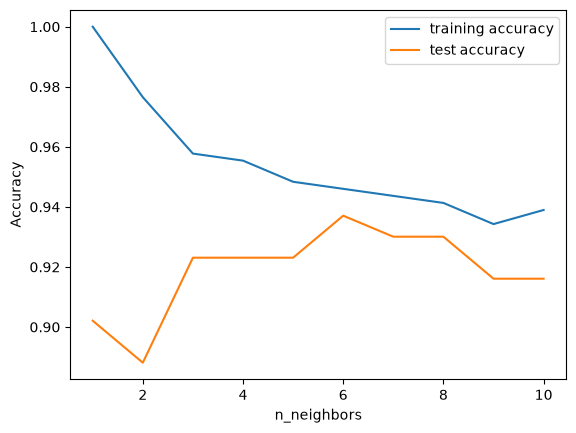

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

cancer = load_breast_cancer()

X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, stratify=cancer.target, random_state=66
)

training_accuracy = []
test_accuracy = []
neighbors_settings = range(1, 11)

for n_neighbors in neighbors_settings:
    clf = KNeighborsClassifier(n_neighbors=n_neighbors)
    clf.fit(X_train, y_train)
    training_accuracy.append(clf.score(X_train, y_train))
    test_accuracy.append(clf.score(X_test, y_test))

plt.plot(neighbors_settings, training_accuracy, label='training accuracy')
plt.plot(neighbors_settings, test_accuracy, label='test accuracy')
plt.ylabel('Accuracy')
plt.xlabel('n_neighbors')
plt.legend()
plt.show()

Dari grafik terlihat saat k = 1 akurasi latih sempurna tetapi akurasi uji menurun, gejala **overfitting**. Semakin banyak tetangga, model semakin sederhana; jumlah tetangga yang baik adalah titik saat akurasi latih dan uji saling berdekatan.

## 2. Naive Bayes

Naive Bayes menghitung peluang suatu label berdasarkan peluang kemunculan tiap fitur menggunakan kaidah Bayes. Persamaan umumnya:

**P(y | x₁, x₂, …, xₙ) = ( P(y) · P(x₁, x₂, …, xₙ | y) ) / P(x₁, x₂, …, xₙ)**

Label dengan peluang terbesar menjadi hasil prediksi. Kata *naif* muncul karena metode ini mengabaikan korelasi antar fitur. Contoh klasik untuk memahami kaidah Bayes adalah soal kegiatan piknik berikut.

In [3]:
# Kaidah Bayes dengan contoh kegiatan piknik
P_hujan = 3 / 30                 # P(A): peluang hujan dalam 30 hari
P_berawan = 0.4                  # P(B): peluang cuaca berawan di pagi hari
P_berawan_given_hujan = 0.5      # P(B|A): hari hujan diawali berawan

P_hujan_given_berawan = P_hujan * P_berawan_given_hujan / P_berawan

print('P(Hujan | Berawan) =', P_hujan_given_berawan)
print(f'Dalam persen: {P_hujan_given_berawan * 100:.1f}%')

P(Hujan | Berawan) = 0.125
Dalam persen: 12.5%


Berdasarkan jenis datanya, Naive Bayes dibedakan menjadi **GaussianNB** untuk data kontinu (berdistribusi normal), **MultinomialNB** untuk data diskrit/hitungan seperti jumlah kata, dan **CategoricalNB** untuk data kategorik. Percobaan berikut memakai GaussianNB pada dua fitur kontinu dataset iris.

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data[:, 2:]   # fitur petal length dan petal width
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
gnb = GaussianNB().fit(X_train, y_train)

print('Akurasi GaussianNB pada data uji:', accuracy_score(y_test, gnb.predict(X_test)))

Akurasi GaussianNB pada data uji: 0.9736842105263158
